In [1]:
# 필요한 라이브러리 설치
%pip install torch torchvision matplotlib

Note: you may need to restart the kernel to use updated packages.


# 라이브러리 준비 및 설정

In [2]:
import os
# OpenMP 라이브러리가 두 번 불러와져도 멈추지 않게
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   

import platform

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

사용 장치: cpu


# 전역 변수 지정

In [3]:
# 분류(10종류의 이미지)
CLASSES = ["티셔츠", "바지", "스웨터", "드레스", "코트", "샌들", "셔츠", "운동화", "가방", "앵클부츠"]
MODEL_FILE = "cnn_fashion.pt"

# 1. 데이터 선택 및 사전 준비

In [4]:
# ---------- 1. 데이터 선택 + 2. 사전 준비 ----------
# ToTensor: 사진(0~255) → 텐서(0~1), 모양 (채널 1, 세로 28, 가로 28)
# 채널 : 1 => 흑백
# 채널 : 3 => 칼라
# Normalize: 0~1 → -1~1 로 가운데를 0에 맞춘다 (스케일링과 같은 이유로 학습이 안정된다)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
train_full = datasets.FashionMNIST("data", train=True, download=False, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=False, transform=transform)
print("학습용:", len(train_full), "시험용:", len(test_data))

image, label = train_full[0] # 첫번째 이미지 가져옴
print("사진 한 장의 모양:", image.shape, "정답:", CLASSES[label])


학습용: 60000 시험용: 10000
사진 한 장의 모양: torch.Size([1, 28, 28]) 정답: 앵클부츠


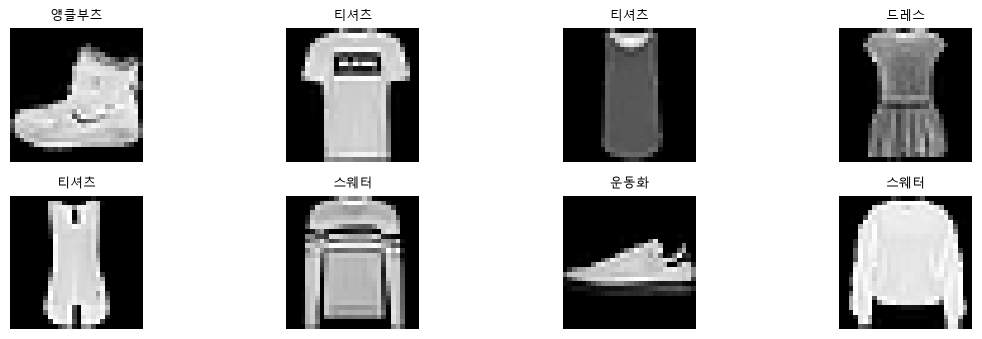

In [10]:
# 데이터 먼저 보기
fig, axes = plt.subplots(2, 4, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    img, lbl = train_full[i]
    ax.imshow(img[0], cmap="gray")
    ax.set_title(CLASSES[lbl], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 훈련/테스트 데이터 분리

In [6]:
# ---------- 3. 훈련, 검증, 테스트 분리 ----------
# 시험용 1만 장은 이미 따로 있다. 학습용 6만 장에서 5천 장을 검증용으로 떼어 둔다.
train_data, valid_data = random_split(train_full, [55000, 5000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)   # 128장씩, 에포크마다 섞어서
valid_loader = DataLoader(valid_data, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

# 학습

In [7]:
# ---------- 4. 학습 ----------
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # 특징 찾기: 합성곱(패턴 찾기) → ReLU(꺾기) → 풀링(크기 줄이기) 을 두 번
        self.features = nn.Sequential(
            # kernel_size 패턴 찾는 돋보기를 3px x 3px로 선택
            # 32 : 패턴의 종류
            # padding : 1, 이미지 위, 아래, 좌, 우에 여백을 추가
            #  => 패딩 없이 필터를 계산하면 이미지가 조금씩 줄어듬
            #  => 패딩을 주어 필터를 거친 이미지가 크기가 줄어들지 않도록
            # 1 : 입력(이미지)
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   
            # ReLu : 활성화 함수 중 하나. 음수이면 0으로 만듬
            # 꺽는 작업 : 음수이면(패턴이 없으면) 없다는 정보를 버리기 위해서 
            nn.ReLU(),
            # 2 : 2 x 2 중에서 가장 큰 값을 가져옴. 
            # MaxPool2d(2) 하는 이유 : 예로 같은 이미지진데 약간 움직여서 조금 다른 경우도 
            # 같은 이미지로 판별수 있게 하기 위해서 
            nn.MaxPool2d(2),                               # 2x2에서 가장 큰 값만 → (32, 14, 14)
            # 앞에서 패턴을 32개 찾았는데, 그걸 이용해서 64개의 패턴으로 특징을 늘림
            nn.Conv2d(32, 64, kernel_size=3, padding=1),   # 앞의 패턴을 조합해 더 큰 패턴 64종류 → (64, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # → (64, 7, 7)
        )
        # 판단하기: 찾은 특징을 한 줄로 펴서 MLP로 10종류 중 하나를 고른다
        self.classifier = nn.Sequential(
            # 이미지를 1차원으로 만듬(한줄로 만듬)
            nn.Flatten(),                                  # (64, 7, 7) → 3136
            # 한줄에 개수 : 특징(64) * 가로(7) * 세로(7)
            # 한 줄로 만든 이미지를 분석해서 128개로 분류
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            # 일부 뉴런(동그라미)을 꺼서 학습을 시킴
            nn.Dropout(0.3),                               # 외우기 방지
            # 128로 분류된 정보를 이용해서 10개로 분류
            nn.Linear(128, 10),                            # 출력층 10 (옷 종류)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = FashionCNN().to(device)
print(model)
print("학습할 숫자:", sum(p.numel() for p in model.parameters()))

# 손실율 계산할 함수 선택
loss_fn = nn.CrossEntropyLoss()   # 여러 개 중 하나 고르기(다중 분류)용. softmax도 이 안에서 한다
# 최적화 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 정확도 계산하는 함수
def accuracy(loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            correct += (model(X).argmax(dim=1) == y).sum().item()
            total += len(y)
    return correct / total


EPOCHS = 8 # 몇 번 반복해서 학습할 건지
best_valid = 0 # 손실이 최소인 검증

for epoch in range(1, EPOCHS + 1):
    model.train() # 학습
    total_loss = 0
    for X, y in train_loader:            # 128장씩
        X, y = X.to(device), y.to(device)
        loss = loss_fn(model(X), y)      # 1. 순전파 2. 손실
        optimizer.zero_grad()
        loss.backward()                  # 3. 역전파
        optimizer.step()                 # 4. 수정
        total_loss += loss.item() * len(y)

    # 학습된 모델로 검증
    valid_acc = accuracy(valid_loader)
    print(f"에포크 {epoch}: 학습 손실 {total_loss / len(train_data):.4f}, 검증 정확도 {valid_acc:.1%}")
    # 최적의 성능을 낸 학습했던 모델을 저장
    if valid_acc > best_valid:           # 조기 종료: 검증 정확도가 가장 좋을 때의 모델을 저장
        best_valid = valid_acc
        torch.save(model.state_dict(), MODEL_FILE)
        print("  → 지금까지 가장 좋아서 저장했습니다")

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
학습할 숫자: 421642
에포크 1: 학습 손실 0.5724, 검증 정확도 86.0%
  → 지금까지 가장 좋아서 저장했습니다
에포크 2: 학습 손실 0.3555, 검증 정확도 88.6%
  → 지금까지 가장 좋아서 저장했습니다
에포크 3: 학습 손실 0.3087, 검증 정확도 89.6%
  → 지금까지 가장 좋아서 저장했습니다
에포크 4: 학습 손실 0.2767, 검증 정확도 90.4%
  → 지금까지 가장 좋아서 저장했습니다
에포크 5: 학습 손실 0.2520, 검증 정확도 90.5%
  → 지금까지 가장 좋아서 저장했습니다
에포크 6: 학습 손실 0.2324, 검증 정확도 91.1%
  → 지금까지 가장 좋아서 저장했습

# 평가

In [8]:
# ---------- 5. 평가 ----------
model.load_state_dict(torch.load(MODEL_FILE))
print(f"\n시험 정확도: {accuracy(test_loader):.1%}  (사진 1만 장, 학습에 한 번도 안 쓴 데이터)")

# 종류별 정확도: 어떤 옷을 헷갈리나
# 0이든 리스트를 10개 만듬 => 한개의 리트스에 0이 10개 저장
correct = [0] * 10 # [0,0,0,0,0,0,0,0,0,0]
total = [0] * 10
model.eval()
with torch.no_grad():
    for X, y in test_loader:
        # 테스트 데이터(여러개. 1만장)를 이용하여 예측
        pred = model(X.to(device)).argmax(dim=1).cpu()
        # 예측 결과와 정답을 이용
        for p, t in zip(pred, y):
            total[t] += 1 # 종류별로 이미지가 각각 총 몇장이었는지
            correct[t] += int(p == t) # 종류별로 맞춘 이미지가 몇장이었는지
print("\n종류별 정확도")
for i, name in enumerate(CLASSES):
    print(f"  {name:6}: {correct[i] / total[i]:.1%}")


시험 정확도: 91.8%  (사진 1만 장, 학습에 한 번도 안 쓴 데이터)

종류별 정확도
  티셔츠   : 89.9%
  바지    : 98.5%
  스웨터   : 87.4%
  드레스   : 92.2%
  코트    : 88.9%
  샌들    : 96.7%
  셔츠    : 71.8%
  운동화   : 97.6%
  가방    : 98.6%
  앵클부츠  : 96.1%


# 예측

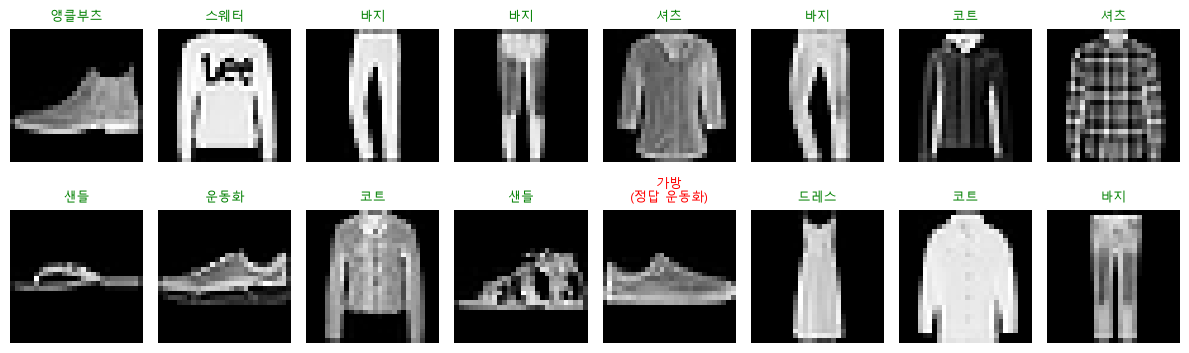

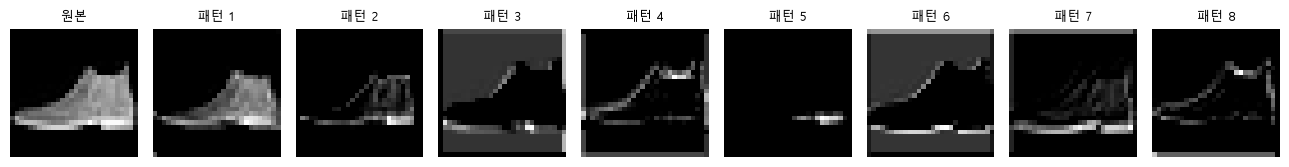

In [12]:
# ---------- 6. 예측 ----------
X_test, y_test = next(iter(test_loader))
with torch.no_grad():
    pred = model(X_test.to(device)).argmax(dim=1).cpu()

# 시험 사진 16장: 제목이 초록이면 맞힘, 빨강이면 틀림 (틀리면 정답도 같이 표시)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i][0], cmap="gray")
    ok = pred[i] == y_test[i]
    title = CLASSES[pred[i]] if ok else f"{CLASSES[pred[i]]}\n(정답 {CLASSES[y_test[i]]})"
    ax.set_title(title, color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# CNN이 보는 것: 첫 번째 합성곱 층이 사진 한 장에서 찾은 패턴 8개
# 밝은 곳 = 그 패턴(가로선, 세로선, 테두리 등)이 강하게 나타난 곳
with torch.no_grad():
    maps = model.features[1](model.features[0](X_test[:1].to(device))).cpu()   # Conv → ReLU
fig, axes = plt.subplots(1, 9, figsize=(13, 1.8))
axes[0].imshow(X_test[0][0], cmap="gray")
axes[0].set_title("원본", fontsize=9)
for i in range(8):
    axes[i + 1].imshow(maps[0, i], cmap="gray")
    axes[i + 1].set_title(f"패턴 {i + 1}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()